Dataset loaded successfully!

First few rows:
   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  
3     7205  31.99         False                  0  Hi-Fi Speakers  
4     1881  17.99         False                  0  Hi-Fi Speakers  

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeI

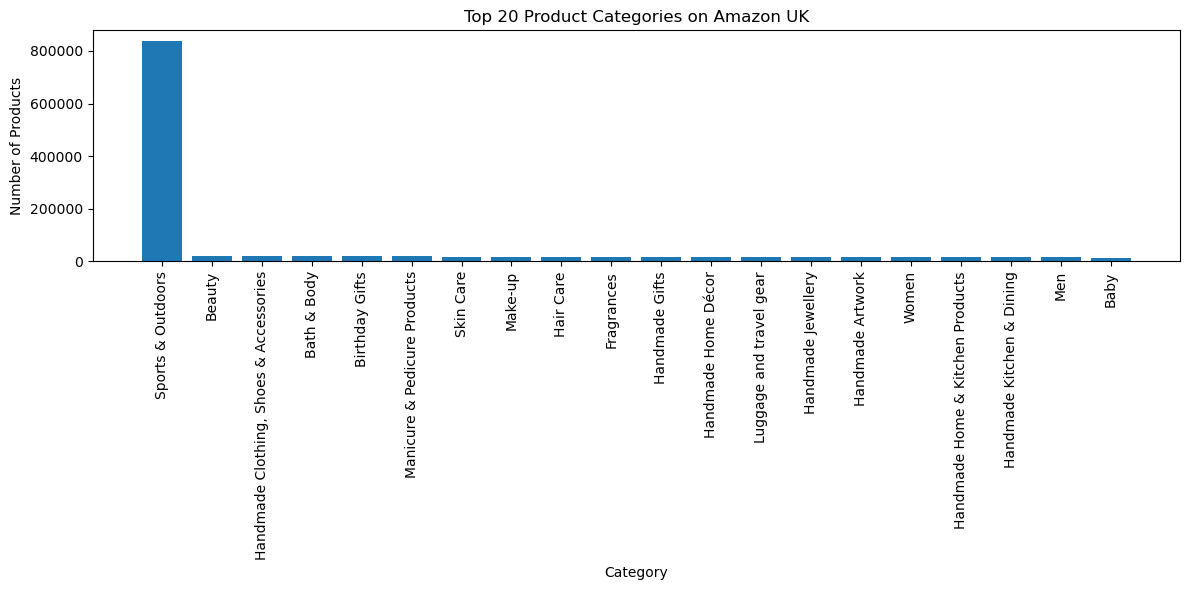


Generating pie chart for top 10 categories...


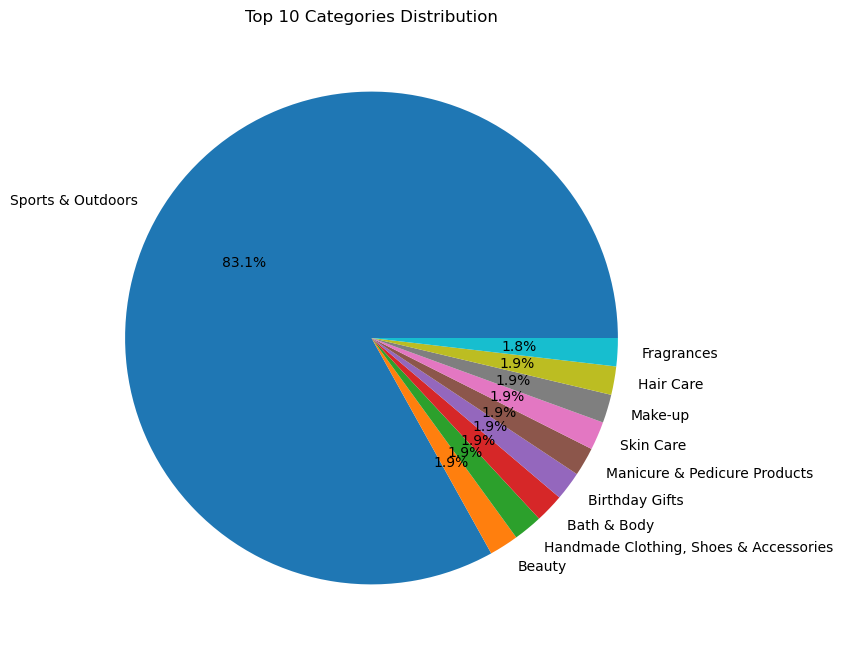


Observation: Check if one category dominates the listings

PART 2 - PRODUCT PRICING

Measures of Centrality:
  Mean price: £89.24
  Median price: £19.09
  Mode price: £9.99

Measures of Dispersion:
  Variance: 119445.49
  Standard Deviation: £345.61
  Range: £100000.00
  IQR: £36.00

Generating histogram of prices...


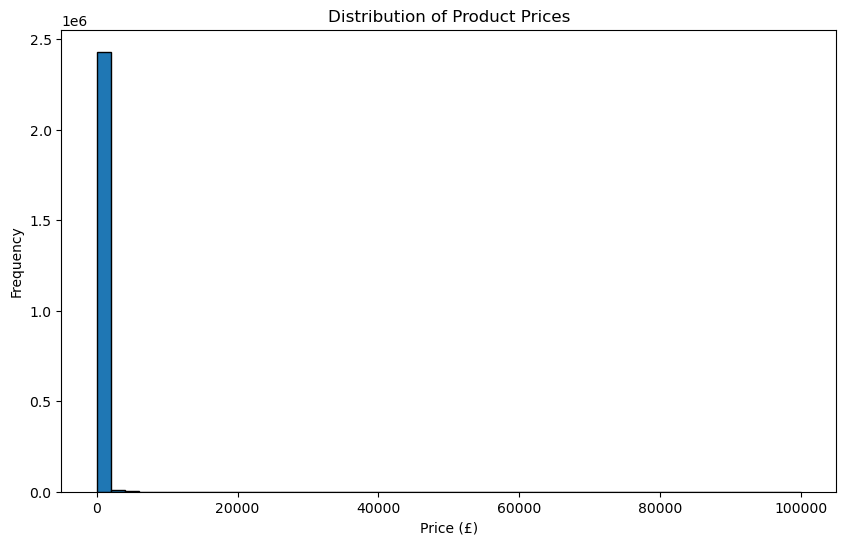

Note: Chart may be hard to read due to expensive outliers

Generating zoomed-in histogram (0-200 range)...


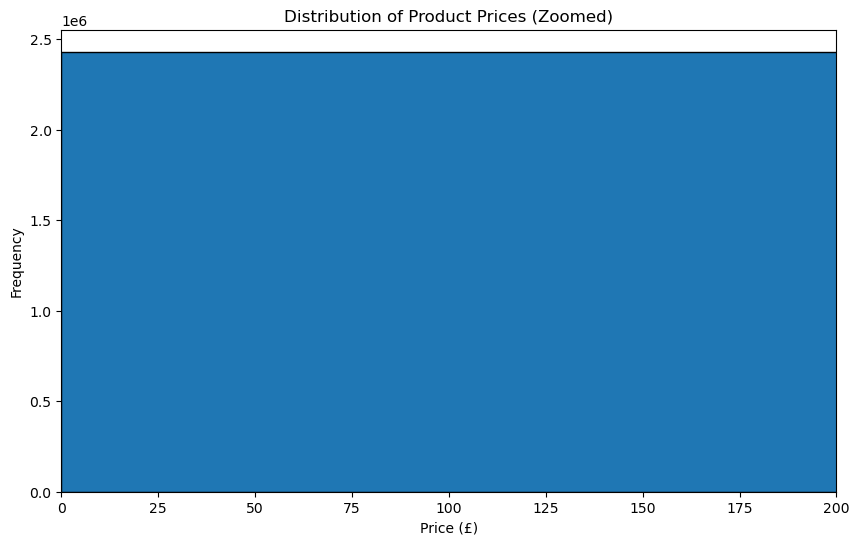


Generating box plot for prices...


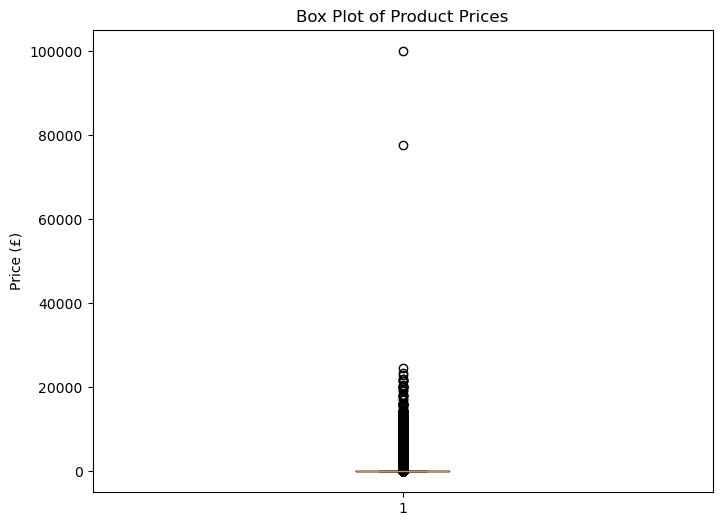

Observation: Box plot shows outliers (premium products)

PART 3 - PRODUCT RATINGS

Measures of Centrality:
  Mean rating: 2.15
  Median rating: 0.00
  Mode rating: 0.00

Measures of Dispersion:
  Variance: 4.8174
  Std Dev: 2.1949
  IQR: 4.40

Shape of Distribution:
  Skewness: 0.0812
  Kurtosis: -1.9260
  -> Ratings are right-skewed (lean towards lower values)

Generating histogram of ratings...


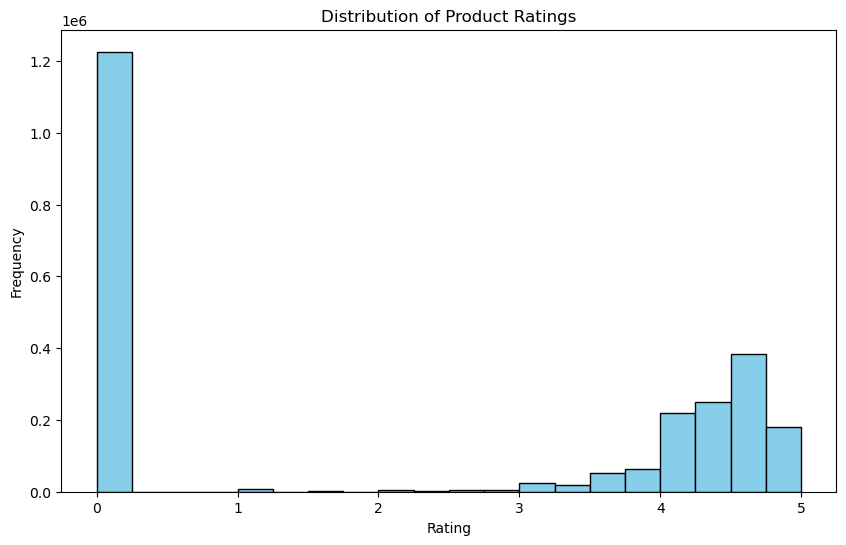


BUSINESS INSIGHTS - AMAZON UK PRODUCTS

1. PRODUCT CATEGORIES
   - Most popular: Sports & Outdoors with 836265 products
   - Top 5 account for significant portion of listings

2. PRICING
   - Average price: £89.24
   - Most common price: £9.99
   - High variation (std: £345.61) indicates diverse pricing
   - Many outliers suggest premium products exist

3. RATINGS
   - Average rating: 2.15/5
   - Ratings are right-skewed (towards lower)
   - Customer satisfaction appears moderate

Analysis complete!


In [3]:
# Lab EDA Univariate Analysis - Amazon UK
# Ross Wilson

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# load the data
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

print("Dataset loaded successfully!")
print("\nFirst few rows:")
print(df.head())
print("\nDataset info:")
print(df.info())

print("\n" + "="*60)
print("PART 1 - PRODUCT CATEGORIES")
print("="*60)

# 1. Frequency table for categories
category_freq = df['category'].value_counts()
print("\nFrequency table for all categories:")
print(category_freq)

#top 5 categories
top5 = category_freq.head(5)
print("\n** Top 5 most listed categories **")
print(top5)

# bar chart for categories - but there's too many so lets do top 20 or something
print("\nGenerating bar chart for top 20 categories...")
top_cats = category_freq.head(20)

plt.figure(figsize=(12,6))
plt.bar(range(len(top_cats)), top_cats.values)
plt.xticks(range(len(top_cats)), top_cats.index, rotation=90)
plt.xlabel('Category')
plt.ylabel('Number of Products')
plt.title('Top 20 Product Categories on Amazon UK')
plt.tight_layout()
plt.show()

# pie chart for top categories (lets do top 10)
print("\nGenerating pie chart for top 10 categories...")
top10_cats = category_freq.head(10)

plt.figure(figsize=(10,8))
plt.pie(top10_cats.values, labels=top10_cats.index, autopct='%1.1f%%')
plt.title('Top 10 Categories Distribution')
plt.show()

print("\nObservation: Check if one category dominates the listings")

print("\n" + "="*60)
print("PART 2 - PRODUCT PRICING")
print("="*60)

# centrality measures
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]  # mode returns a series so get first value

print("\nMeasures of Centrality:")
print(f"  Mean price: £{mean_price:.2f}")
print(f"  Median price: £{median_price:.2f}")
print(f"  Mode price: £{mode_price:.2f}")

# dispersion measures for price
variance = df['price'].var()
std_dev = df['price'].std()
price_range = df['price'].max() - df['price'].min()

q1 = df['price'].quantile(0.25)
q3 = df['price'].quantile(0.75)
iqr = q3 - q1

print("\nMeasures of Dispersion:")
print(f"  Variance: {variance:.2f}")
print(f"  Standard Deviation: £{std_dev:.2f}")
print(f"  Range: £{price_range:.2f}")
print(f"  IQR: £{iqr:.2f}")

# histogram of prices
print("\nGenerating histogram of prices...")
plt.figure(figsize=(10,6))
plt.hist(df['price'], bins=50, edgecolor='black')
plt.xlabel('Price (£)')
plt.ylabel('Frequency')
plt.title('Distribution of Product Prices')
plt.show()

print("Note: Chart may be hard to read due to expensive outliers")

# lets try again with a limit
print("\nGenerating zoomed-in histogram (0-200 range)...")
plt.figure(figsize=(10,6))
plt.hist(df['price'], bins=50, edgecolor='black')
plt.xlabel('Price (£)')
plt.ylabel('Frequency')
plt.title('Distribution of Product Prices (Zoomed)')
plt.xlim(0, 200)  # zoom in on most of the data
plt.show()

#box plot for prices
print("\nGenerating box plot for prices...")
plt.figure(figsize=(8,6))
plt.boxplot(df['price'])
plt.ylabel('Price (£)')
plt.title('Box Plot of Product Prices')
plt.show()

print("Observation: Box plot shows outliers (premium products)")

print("\n" + "="*60)
print("PART 3 - PRODUCT RATINGS")
print("="*60)

# centrality for stars
mean_stars = df['stars'].mean()
median_stars = df['stars'].median()
mode_stars = df['stars'].mode()[0]

print("\nMeasures of Centrality:")
print(f"  Mean rating: {mean_stars:.2f}")
print(f"  Median rating: {median_stars:.2f}")
print(f"  Mode rating: {mode_stars:.2f}")

# dispersion for stars
stars_var = df['stars'].var()
stars_std = df['stars'].std()

q1_stars = df['stars'].quantile(0.25)
q3_stars = df['stars'].quantile(0.75)
iqr_stars = q3_stars - q1_stars

print("\nMeasures of Dispersion:")
print(f"  Variance: {stars_var:.4f}")
print(f"  Std Dev: {stars_std:.4f}")
print(f"  IQR: {iqr_stars:.2f}")

# skewness and kurtosis
skew = df['stars'].skew()
kurt = df['stars'].kurtosis()

print("\nShape of Distribution:")
print(f"  Skewness: {skew:.4f}")
print(f"  Kurtosis: {kurt:.4f}")

if skew < 0:
    print("  -> Ratings are left-skewed (lean towards higher values)")
elif skew > 0:
    print("  -> Ratings are right-skewed (lean towards lower values)")
else:
    print("  -> Ratings are roughly symmetric")

# histogram of stars
print("\nGenerating histogram of ratings...")
plt.figure(figsize=(10,6))
plt.hist(df['stars'], bins=20, edgecolor='black', color='skyblue')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.title('Distribution of Product Ratings')
plt.show()

print("\n" + "="*60)
print("BUSINESS INSIGHTS - AMAZON UK PRODUCTS")
print("="*60)
print()
print("1. PRODUCT CATEGORIES")
print(f"   - Most popular: {top5.index[0]} with {top5.values[0]} products")
print(f"   - Top 5 account for significant portion of listings")
print()
print("2. PRICING")
print(f"   - Average price: £{mean_price:.2f}")
print(f"   - Most common price: £{mode_price:.2f}")
print(f"   - High variation (std: £{std_dev:.2f}) indicates diverse pricing")
print(f"   - Many outliers suggest premium products exist")
print()
print("3. RATINGS")
print(f"   - Average rating: {mean_stars:.2f}/5")
print(f"   - Ratings are {'left-skewed (towards higher)' if skew < 0 else 'right-skewed (towards lower)'}")
print(f"   - Customer satisfaction appears {'high' if mean_stars > 4 else 'moderate'}")
print("\nAnalysis complete!")